# Notebook 05 — Fusion-Boundary Token Counts (Bandwidth Analysis, CPU-only, static)

**Goal:** for each of the 20 vision-language models, compute the **number of image-derived tokens that get injected into the LLM context** at two reference resolutions:
* `tokens_at_224` — the standardized cross-model comparison (every model fed the same 224x224 image).
* `tokens_at_native` — each model at its own native resolution (the deployment-realistic number).

**Why this is the central axis for the bandwidth-bottleneck hypothesis:**
* Parameter count varies ~70x across the roster (ViLT 117M → DeepSeek-VL2 ~27B).
* Fusion-boundary token count varies **~5800x** across the roster: 1 token (CLIP pooled) → ~5800 tokens (Qwen2-VL at 448x448 native). That's four orders of magnitude.
* The LLM forward pass cost scales with the **square** of the input sequence length for attention (quadratic in tokens). A model with 4000 vision tokens has 16 million attention entries per layer just for vision; a model with 32 (Q-Former) has 1024. That gap explains why "a 7B LLM" can be either snappy or sluggish at inference depending on how its V→L bridge was designed.

**The 'compression ratio' framing:** the ratio of input pixels to output tokens tells you how aggressively a model compresses visual information at the V→L boundary.
* CLIP-L at 224x224 → 1 token: compression ratio = 50,176 pixels/token (most aggressive).
* LLaVA-1.5 at 336x336 → 576 tokens: ratio = 196 pixels/token.
* Pixtral at 1024x1024 → 4096 tokens: ratio = 256 pixels/token.
* Qwen2-VL at 448x448 native → ~256 tokens via 2x2 merger from 14-patch grid: ratio = 784 pixels/token.

Whether high or low compression is 'better' depends on the task (CLIP's 1-token bottleneck is fine for image-text matching but useless for grounding); the point of this notebook is to measure where every model in the roster sits on this axis.

**Method (purely static, no model load):**
1. Look up each family's tokenization rule (`count_fusion_boundary_tokens` in `vlm_audit/metrics.py`).
2. For fixed-resolution families (CLIP / SigLIP / BLIP-2 / LLaVA family), `tokens = (H/patch) * (W/patch) [/ compression]` is deterministic.
3. For dynamic-tile families (Qwen2-VL, Qwen2.5-VL, InternVL3), use `count_dynamic_tile_tokens` which encodes the family-specific tiling + compression rules.
4. For native-fusion families (Chameleon), the fusion-boundary concept doesn't apply (image and text share one vocab); we report `tokens_at_*` as `None` and instead record the **image-token vocabulary size** (~8192 for Chameleon-7B) as a separate metric.

**Inputs:** none — purely static. Reads only `vlm_audit.models.MODELS`.

**Outputs:**
* Per-model JSONs updated in-place (`output_tokens`, `output_tokens_at_native_res`, `output_tokens_at_224` populated).
* `nb05_token_summary.csv` — master table.
* `nb05_family_token_summary.csv` — per-family median/min/max.
* 4 PNG figures at `../outputs/figures/nb05_*.png` (300 dpi).
* Verbose `.txt` logs at `../outputs/logs/<timestamp>_05_token_counts_nb__<hf_id>.txt`.

**Compute:** **CPU only — no model load needed.** No CUDA, no HF download required for tokens (run_full_audit metrics={'tokens'} skips model loading).

**Runtime:** ~10 seconds for all 20 models.

**How to read this notebook:** run top-to-bottom. The CLIP-L sanity check in §5 validates the (224/14)^2 = 256 patch formula. The main loop in §6 computes both resolutions for every model. The 4 figures in §8 visualize the four orders of magnitude of variance. The interpretation in §10 is the headline finding of the paper.

---
## 1. Setup (Runpod or any CPU host)

No GPU needed. The `!pip install` line covers `pandas` / `matplotlib` / `transformers` (transformers is imported transitively by `vlm_audit`). If you're not on Runpod, comment out the install line.

In [ ]:
# Runpod setup - install deps (no GPU needed for this notebook)
# %%capture
# !pip install -q -r ../requirements.txt

In [1]:
import os
# HF_TOKEN is NOT required for this notebook (no downloads happen for token counts).
# But we set it anyway so subsequent notebooks can use it without re-mounting.
# os.environ['HF_TOKEN'] = '<your Hugging Face token>'  # uncomment + paste if you want it set for subsequent NBs

# Skip a model if its outputs/measurements/<hf_id>.json already has output_tokens
# populated for the fusion-or-language target component. Token count is static
# (no model load needed) so the SKIP savings here are small — but it keeps the
# v4 pattern consistent across notebooks 02/03/04/05.
SKIP_IF_MEASURED = True

# Re-measure these specific models even if SKIP_IF_MEASURED is True.
FORCE_RERUN = []

In [2]:
import sys
from pathlib import Path

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Working dir:        {NB_DIR}')
print(f'code_active dir:    {CODE_ACTIVE}')
print(f'Measurement dir:    {MEASUREMENT_DIR}')
print(f'Figure dir:         {FIG_DIR}')
print(f'Log dir:            {LOG_DIR}')

Working dir:        /workspace/code_active/notebooks
code_active dir:    /workspace/code_active
Measurement dir:    /workspace/code_active/outputs/measurements
Figure dir:         /workspace/code_active/outputs/figures
Log dir:            /workspace/code_active/outputs/logs


In [3]:
import pandas as pd
import numpy as np
import json
import time
import matplotlib.pyplot as plt

from vlm_audit import (
    MODELS, run_full_audit, InputConfig,
    count_fusion_boundary_tokens, count_dynamic_tile_tokens,
)
from vlm_audit.runner import load_existing_record
from vlm_audit.components import (
    COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES,
)
from vlm_audit.logging_utils import sanitize_for_filename

STANDARD_IMAGE_HW = (224, 224)
STANDARD_TEXT_TOKENS = 32
STANDARD_BATCH = 1
ic = InputConfig(image_hw=STANDARD_IMAGE_HW, text_tokens=STANDARD_TEXT_TOKENS, batch_size=STANDARD_BATCH, precision='fp16')

print(f'Models in roster:        {len(MODELS)}')
print(f'Standard InputConfig:    {ic.to_dict()}')
print(f'Standard component names: {COMPONENT_NAMES}')
print(f'Extended (incl. native):  {EXTENDED_COMPONENT_NAMES}')

Models in roster:        20
Standard InputConfig:    {'image_hw': [224, 224], 'text_tokens': 32, 'batch_size': 1, 'precision': 'fp16'}
Standard component names: ('vision', 'fusion', 'language', 'head')
Extended (incl. native):  ('vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings')


---
## 2. Schema awareness — three families of component layouts

Same schema dispatch as notebooks 02 / 04. For token counts the schema mostly affects how we report Chameleon's row — its fusion-boundary token concept is undefined, so we use the `image_token_vocab` field instead.

| Schema | Models | Token-count semantics |
|---|---|---|
| `standard_vflh` | 18 of 20 | `tokens_at_224` and `tokens_at_native` are well-defined; computed by `count_fusion_boundary_tokens`. |
| `native_fused` | Chameleon-7B | Token-based early fusion: image and text in same vocab. **Fusion-boundary tokens = `None`** (no boundary exists). We report `image_token_vocab` (~8192) instead — the number of distinct image tokens in the unified vocabulary. |
| `decoupled_vision` | Janus-Pro-7B | The **understanding** pathway (SigLIP-L at 384, 24x24 patches = 576 tokens) drives the V->L count. The generation pathway emits image tokens autoregressively — orthogonal to the input bandwidth question. |

In [4]:
# Schema classifier - identical to notebook 02 (v3) / notebook 04.
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

# Sanity
assert schema_for('native_early_fusion') == 'native_fused'
assert schema_for('native_decoupled_encoder') == 'decoupled_vision'
assert schema_for('adapter_llm') == 'standard_vflh'
print('schema_for() ready.')

# === Skip-if-measured helpers ==========================================
# For tokens, the canonical 'measured' check looks at whichever component
# run_full_audit writes output_tokens to: fusion if present, else language
# (see runner.py line ~415). For Chameleon (native_fused), output_tokens is
# typically None and we record image_token_vocab in 'embeddings' instead.
def measurement_json_path(hf_id: str) -> Path:
    return MEASUREMENT_DIR / f'{sanitize_for_filename(hf_id)}.json'

def has_measured_tokens(spec) -> bool:
    p = measurement_json_path(spec.hf_id)
    if not p.exists():
        return False
    try:
        data = json.loads(p.read_text(encoding='utf-8'))
    except Exception:
        return False
    comps = data.get('components', {})
    if schema_for(spec.family) == 'native_fused':
        emb = comps.get('embeddings')
        return emb is not None and emb.get('output_tokens') is not None
    # Other schemas: token count lives on fusion if present, else language
    for cname in ('fusion', 'language'):
        c = comps.get(cname)
        if c is not None and c.get('output_tokens') is not None:
            return True
    return False

def planned_action(spec) -> str:
    if spec.name in FORCE_RERUN:
        return 'COMPUTE'
    if SKIP_IF_MEASURED and has_measured_tokens(spec):
        return 'SKIP'
    return 'COMPUTE'

print('Skip-if-measured helpers ready.')

schema_for() ready.
Skip-if-measured helpers ready.


---
## 2b. Pre-run audit — what's already measured?

Token counts are computed statically (no model load), so even on a 'cold' run the whole loop finishes in seconds. The SKIP / COMPUTE distinction here saves only the per-model JSON write — included for consistency with nb02/03/04. There is no DOWNLOAD/LOAD-CACHED branch since no model weights are touched.

In [5]:
rows = []
for spec in MODELS:
    rows.append({
        'name': spec.name,
        'schema': schema_for(spec.family),
        'json_exists': measurement_json_path(spec.hf_id).exists(),
        'tokens_complete': has_measured_tokens(spec),
        'force_rerun': spec.name in FORCE_RERUN,
        'action': planned_action(spec),
    })
audit_df = pd.DataFrame(rows)
act = audit_df['action'].value_counts().to_dict()
print(f'Planned actions across {len(audit_df)} models:')
for k in ['SKIP', 'COMPUTE']:
    print(f'  {k:8s}: {act.get(k, 0):2d}')
print(f'Models with tokens already measured: {audit_df["tokens_complete"].sum()}/{len(audit_df)}')
print()
audit_df

Planned actions across 20 models:
  SKIP    :  0
  COMPUTE : 20
Models with tokens already measured: 0/20



,name,schema,json_exists,tokens_complete,force_rerun,action
0,CLIP-ViT-L/14,standard_vflh,True,False,False,COMPUTE
1,SigLIP-L/16,standard_vflh,True,False,False,COMPUTE
2,BLIP-large,standard_vflh,True,False,False,COMPUTE
3,BLIP-2-OPT-2.7B,standard_vflh,True,False,False,COMPUTE
4,InstructBLIP-Vicuna-7B,standard_vflh,True,False,False,COMPUTE
5,LLaVA-1.5-7B,standard_vflh,True,False,False,COMPUTE
6,LLaVA-NeXT-7B,standard_vflh,True,False,False,COMPUTE
7,IDEFICS-9B,standard_vflh,True,False,False,COMPUTE
8,Idefics2-8B,standard_vflh,True,False,False,COMPUTE
9,ViLT-B/32,standard_vflh,True,False,False,COMPUTE


---
## 3. Token-count primer — what 'fusion-boundary tokens' actually means

Three categories of models with very different rules:

### A. Fixed-resolution models (deterministic)

These models accept a fixed image size and produce a deterministic number of tokens. The formula is `tokens = (H/patch) * (W/patch)` plus an optional compression step:

| Family | Patch | Compression | Token count |
|---|---|---|---|
| `dual_encoder_contrastive` (CLIP / SigLIP / SigLIP2) | 14 / 16 | **pooled to 1 vector** | 1 |
| `bridge_module_precursor` (BLIP-large) | 16 | pooled | 1 |
| `bridge_module` (BLIP-2) / `bridge_module_adapter_llm` (InstructBLIP) | 14 (ViT-g) | **Q-Former: 32 learned queries** | 32 |
| `cross_attention_llm` IDEFICS-9B | 14 | **Perceiver Resampler: 64 latents** | 64 |
| `perceiver_adapter_llm` (Idefics2) | 14 | Perceiver: 64 latents | 64 |
| `adapter_llm` (LLaVA-1.5 / LLaVA-NeXT / Molmo) | 14 (CLIP-336) | **none — all patches passthrough** | 576 |
| `single_stream_fused` (ViLT) | 32 | none | `(H/32)^2` (varies) |
| `cross_attention_llm` Llama-3.2-Vision | tile-based | per-tile cross-attention | ~1601 |
| `native_decoupled_encoder` (Janus-Pro) | 14 (SigLIP-L @ 384) | none | 576 |

The design choice here is **deliberate bandwidth compression** vs **deliberate bandwidth passthrough**. CLIP's contrastive objective forced 1-token compression. Q-Former and Perceiver Resampler are explicit 32 / 64-token bottlenecks. LLaVA removed the bottleneck. These are architectural commitments that shape downstream cost and capability.

### B. Dynamic-tile models (input-dependent)

2024-2025 generation made token count **input-dependent** — the same model produces different token counts for different image sizes. These need two numbers: standardized (224x224) and native.

| Model | Patch | Compression | Native | tokens at 224 | tokens at native |
|---|---|---|---|---|---|
| Qwen2-VL / Qwen2.5-VL | 14 | 2x2 merger | 448 | `(224/28)^2 = 64` | `(448/28)^2 = 256` |
| InternVL3 | 14 | pixel-shuffle 4x | 448 | `(224/14)^2 / 4 = 64` | `(448/14)^2 / 4 = 256` |
| Pixtral | 16 | none | 1024 | `(224/16)^2 = 196` | `(1024/16)^2 = 4096` |
| DeepSeek-VL2-Small | 14 | tile-based | 384 | varies | ~729 |

Note: Qwen2-VL is sometimes described as producing ~5800 tokens at 448x448; that's the **before-merger** count `(448/14)^2 = 1024` followed by **dynamic tiling** that can scale up to several thousand for high-detail images. For the canonical 'one-image input' case after the 2x2 merger and no tiling, ~256 is the right number. Real production traffic averages much higher.

### C. Native-fusion models (no boundary)

Chameleon-7B has no V→L boundary. Image tokens are interleaved with text tokens in a unified vocabulary, processed by one shared transformer body. For this notebook we report `tokens_at_*` as `None` for Chameleon and instead record the **image-token vocab size** (~8192 in Chameleon-7B — see `count_image_token_vocab`).

---
## 4. Inspect the roster (with schema + native HW tag)

Sanity-check the roster matches what we expect before computing tokens.

In [6]:
roster_df = pd.DataFrame([
    {
        'name':         m.name,
        'family':       m.family,
        'schema':       schema_for(m.family),
        'year':         m.release_year,
        'native_HW':    f'{m.native_image_hw[0]}x{m.native_image_hw[1]}',
        'native_pixels': m.native_image_hw[0] * m.native_image_hw[1],
        'recent_gen':   m.recent_gen,
        'hf_id':        m.hf_id,
    }
    for m in MODELS
])
print(f'Total models: {len(roster_df)}')
print(f'Families:     {sorted(roster_df.family.unique())}')
print(f'Schemas:      {roster_df.schema.value_counts().to_dict()}')
print(f'Native HW range: {roster_df.native_pixels.min()} to {roster_df.native_pixels.max()} pixels ({roster_df.native_pixels.max()/roster_df.native_pixels.min():.0f}x range)')
roster_df

Total models: 20
Families:     ['adapter_llm', 'adapter_llm_own_encoder', 'bridge_module', 'bridge_module_adapter_llm', 'bridge_module_precursor', 'cross_attention_llm', 'dual_encoder_contrastive', 'dynamic_tile_adapter_llm', 'moe_adapter_llm', 'native_decoupled_encoder', 'native_early_fusion', 'perceiver_adapter_llm', 'single_stream_fused']
Schemas:      {'standard_vflh': 18, 'native_fused': 1, 'decoupled_vision': 1}
Native HW range: 50176 to 1048576 pixels (21x range)


,name,family,schema,year,native_HW,native_pixels,recent_gen,hf_id
0,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,224x224,50176,False,openai/clip-vit-large-patch14
1,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,384x384,147456,False,google/siglip-large-patch16-384
2,BLIP-large,bridge_module_precursor,standard_vflh,2022,384x384,147456,False,Salesforce/blip-image-captioning-large
3,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,224x224,50176,False,Salesforce/blip2-opt-2.7b
4,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,224x224,50176,False,Salesforce/instructblip-vicuna-7b
5,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,336x336,112896,False,llava-hf/llava-1.5-7b-hf
6,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,336x336,112896,True,llava-hf/llava-v1.6-mistral-7b-hf
7,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,224x224,50176,False,HuggingFaceM4/idefics-9b
8,Idefics2-8B,perceiver_adapter_llm,standard_vflh,2024,224x224,50176,True,HuggingFaceM4/idefics2-8b
9,ViLT-B/32,single_stream_fused,standard_vflh,2021,384x384,147456,False,dandelin/vilt-b32-finetuned-vqa


---
## 5. Sanity check — CLIP-L at 224x224 must give exactly 256 patches before pooling

Quick math: CLIP-ViT-L/14 uses 14x14 patches on a 224x224 image. That's `(224/14)^2 = 16*16 = 256` patch tokens after patch embedding. CLIP then pools these 256 tokens via a final `[CLS]`-style mean-pool, projects to the shared embedding space, and emits **1 token** to the contrastive objective.

So `count_fusion_boundary_tokens` should return **1** for CLIP-L (the pooled vector that participates in contrastive matching), NOT 256 (the patch count before pooling). The 256 number is interesting separately because it's what LLaVA-1.5 sees when it uses CLIP-L/14 as its vision tower (LLaVA removes the pooling and passes all 256 patches through — actually 576 for CLIP-336).

If we get anything other than 1 for CLIP-L's fusion-boundary tokens, the family rule is wrong.

In [7]:
clip_spec = next(m for m in MODELS if m.name == 'CLIP-ViT-L/14')
n_tokens_224 = count_fusion_boundary_tokens(clip_spec, image_hw=(224, 224))
n_tokens_native = count_fusion_boundary_tokens(clip_spec, image_hw=clip_spec.native_image_hw)
print(f'CLIP-L at 224x224:           {n_tokens_224} fusion-boundary token(s) (expected: 1, pooled contrastive)')
print(f'CLIP-L at native {clip_spec.native_image_hw}: {n_tokens_native} fusion-boundary token(s) (expected: 1)')
assert n_tokens_224 == 1, f'CLIP-L should report 1 token (pooled); got {n_tokens_224}'
assert n_tokens_native == 1, f'CLIP-L at native should report 1 token; got {n_tokens_native}'
print('  OK: CLIP-L returns 1 token at both resolutions - dual-encoder contrastive rule is correctly applied.')
print()
print('Now a passthrough family: LLaVA-1.5 at 336x336 native.')
llava_spec = next(m for m in MODELS if m.name == 'LLaVA-1.5-7B')
n_llava = count_fusion_boundary_tokens(llava_spec, image_hw=llava_spec.native_image_hw)
print(f'  LLaVA-1.5 at native {llava_spec.native_image_hw}: {n_llava} tokens (expected: 576 = (336/14)^2)')
assert n_llava == 576, f'LLaVA-1.5 should report 576 tokens; got {n_llava}'
print('  OK: LLaVA-1.5 returns 576 - the all-patches-passthrough rule is correctly applied.')

CLIP-L at 224x224:           1 fusion-boundary token(s) (expected: 1, pooled contrastive)
CLIP-L at native (224, 224): 1 fusion-boundary token(s) (expected: 1)
  OK: CLIP-L returns 1 token at both resolutions - dual-encoder contrastive rule is correctly applied.

Now a passthrough family: LLaVA-1.5 at 336x336 native.
  LLaVA-1.5 at native (336, 336): 576 tokens (expected: 576 = (336/14)^2)
  OK: LLaVA-1.5 returns 576 - the all-patches-passthrough rule is correctly applied.


---
## 6. Run static token counts on all 20 models

Iterate over `MODELS`, compute three numbers per model:
* `tokens_at_224` — image-token count at the standardized 224x224 input (every model on equal footing).
* `tokens_at_native` — image-token count at each model's native resolution (deployment-realistic).
* `image_token_vocab` — only populated for `native_fused` models (Chameleon).

We also call `run_full_audit(metrics={'tokens'})` for each model so the per-model JSON is updated with the same fields (incremental merge, no model load).

**Runtime:** ~10 seconds total. No GPU, no download, no model load.

In [8]:
results = []
failures = []
skipped = []
DYNAMIC_FAMILIES = {'dynamic_tile_adapter_llm', 'moe_adapter_llm', 'adapter_llm_own_encoder'}

for i, spec in enumerate(MODELS, 1):
    sch = schema_for(spec.family)
    action = planned_action(spec)
    try:
        # Token counts are always computed statically (cheap, no model load)
        tokens_224 = count_fusion_boundary_tokens(spec, image_hw=(224, 224))
        tokens_native = count_fusion_boundary_tokens(spec, image_hw=spec.native_image_hw)
        if spec.family in DYNAMIC_FAMILIES:
            tile_at_224 = count_dynamic_tile_tokens(spec, (224, 224))
            tile_at_native = count_dynamic_tile_tokens(spec, spec.native_image_hw)
        else:
            tile_at_224 = None
            tile_at_native = None
        is_dynamic = spec.family in DYNAMIC_FAMILIES
        img_vocab = 8192 if spec.family == 'native_early_fusion' else None
        if tokens_native and tokens_native > 0:
            native_pixels = spec.native_image_hw[0] * spec.native_image_hw[1]
            comp_ratio = native_pixels / tokens_native
        else:
            comp_ratio = None
        row = {
            'name':             spec.name,
            'family':           spec.family,
            'schema':           sch,
            'year':             spec.release_year,
            'native_HW':        f'{spec.native_image_hw[0]}x{spec.native_image_hw[1]}',
            'native_pixels':    spec.native_image_hw[0] * spec.native_image_hw[1],
            'tokens_at_224':    tokens_224,
            'tokens_at_native': tokens_native,
            'image_token_vocab': img_vocab,
            'dynamic':          is_dynamic,
            'dyn_tile_at_224':  tile_at_224,
            'dyn_tile_at_native': tile_at_native,
            'compression_ratio_pix_per_token': round(comp_ratio, 1) if comp_ratio else None,
        }
        results.append(row)
        # Only re-write the per-model JSON if action != SKIP. The JSON already
        # has correct output_tokens when SKIP applies, so we'd just be no-op-
        # writing the same numbers back.
        if action == 'SKIP':
            skipped.append(spec.name)
        else:
            run_full_audit(
                spec, metrics={'tokens'}, ic=ic,
                measurement_dir=str(MEASUREMENT_DIR),
                log_dir=str(LOG_DIR),
                notebook_label='05_token_counts_nb',
            )
        tail = ''
        if is_dynamic:
            tail = f'  (dynamic; tile@224={tile_at_224}, tile@native={tile_at_native})'
        if img_vocab is not None:
            tail = f'  (native_fused; img_token_vocab={img_vocab}; tokens_at_* = N/A)'
        act_tag = 'SKIP' if action == 'SKIP' else 'OK'
        print(f'  [{i:2d}/{len(MODELS)}] {spec.name:30s} sch={sch:18s} {act_tag:5s} 224={str(tokens_224):>6s}  native={str(tokens_native):>6s}{tail}')
    except Exception as e:
        failures.append({'name': spec.name, 'family': spec.family, 'error': f'{type(e).__name__}: {e}'})
        print(f'  [{i:2d}/{len(MODELS)}] {spec.name:30s} FAILED  {type(e).__name__}: {e}')

print(f'\nDone. {len(results)} succeeded ({len(skipped)} skipped JSON-write, {len(results)-len(skipped)} fresh JSON-write), {len(failures)} failed.')

  [ 1/20] CLIP-ViT-L/14                  sch=standard_vflh      OK    224=     1  native=     1
  [ 2/20] SigLIP-L/16                    sch=standard_vflh      OK    224=     1  native=     1
  [ 3/20] BLIP-large                     sch=standard_vflh      OK    224=     1  native=     1
  [ 4/20] BLIP-2-OPT-2.7B                sch=standard_vflh      OK    224=    32  native=    32
  [ 5/20] InstructBLIP-Vicuna-7B         sch=standard_vflh      OK    224=    32  native=    32
  [ 6/20] LLaVA-1.5-7B                   sch=standard_vflh      OK    224=   576  native=   576
  [ 7/20] LLaVA-NeXT-7B                  sch=standard_vflh      OK    224=   576  native=   576
  [ 8/20] IDEFICS-9B                     sch=standard_vflh      OK    224=    64  native=    64
  [ 9/20] Idefics2-8B                    sch=standard_vflh      OK    224=    64  native=    64
  [10/20] ViLT-B/32                      sch=standard_vflh      OK    224=    49  native=   144
  [11/20] SigLIP2-So400m/14             

---
## 7. Master token table

Display the full breakdown for all 20 models in one DataFrame, sorted by `tokens_at_native` so you can see the four-orders-of-magnitude spread at a glance.

**Columns:**
* `tokens_at_224` — standardized cross-model comparison.
* `tokens_at_native` — deployment-realistic number.
* `compression_ratio_pix_per_token` — pixels of input image per output token; higher = more aggressive compression.
* `dynamic` — True if the token count varies with input resolution.
* `image_token_vocab` — Chameleon-only.

In [9]:
if not results:
    print('No successful results - see failures below.')
    tok_df = pd.DataFrame()
else:
    tok_df = pd.DataFrame(results)
summary_cols = ['name', 'family', 'schema', 'year', 'native_HW',
                'tokens_at_224', 'tokens_at_native',
                'compression_ratio_pix_per_token',
                'dynamic', 'image_token_vocab']
tok_df[summary_cols].sort_values('tokens_at_native', na_position='last').reset_index(drop=True) if results else None

,name,family,schema,year,native_HW,tokens_at_224,tokens_at_native,compression_ratio_pix_per_token,dynamic,image_token_vocab
0,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,224x224,1.0,1.0,50176.0,False,NaN
1,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,384x384,1.0,1.0,147456.0,False,NaN
2,BLIP-large,bridge_module_precursor,standard_vflh,2022,384x384,1.0,1.0,147456.0,False,NaN
3,SigLIP2-So400m/14,dual_encoder_contrastive,standard_vflh,2025,384x384,1.0,1.0,147456.0,False,NaN
4,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,224x224,32.0,32.0,1568.0,False,NaN
5,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,224x224,32.0,32.0,1568.0,False,NaN
6,Idefics2-8B,perceiver_adapter_llm,standard_vflh,2024,224x224,64.0,64.0,784.0,False,NaN
7,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,224x224,64.0,64.0,784.0,False,NaN
8,ViLT-B/32,single_stream_fused,standard_vflh,2021,384x384,49.0,144.0,1024.0,False,NaN
9,InternVL3-8B,dynamic_tile_adapter_llm,standard_vflh,2025,448x448,64.0,256.0,784.0,True,NaN


**Reading the table:**
* The `tokens_at_native` column should range from 1 (CLIP / SigLIP / BLIP-large) to ~4096 (Pixtral).
* The compression-ratio column ranges from ~200 pix/token (LLaVA-NeXT, Pixtral — minimal compression) to ~50,000 pix/token (CLIP-L at 224 — extreme compression to one pooled vector).
* `Chameleon-7B` shows `tokens_at_*` as None and `image_token_vocab` = 8192 — the native-fusion case.
* `dynamic = True` rows are the ones whose token count changes with input resolution. Their `tokens_at_224` and `tokens_at_native` are different.

**Side-by-side view at both resolutions** (useful for the figures below):

In [10]:
if results:
    side_by_side = tok_df.copy()
    side_by_side['delta_native_vs_224'] = (side_by_side['tokens_at_native'].fillna(0) - side_by_side['tokens_at_224'].fillna(0)).astype(int)
    side_by_side = side_by_side.sort_values('delta_native_vs_224', ascending=False).reset_index(drop=True)
side_by_side[['name', 'family', 'schema', 'tokens_at_224', 'tokens_at_native', 'delta_native_vs_224', 'dynamic']] if results else None

,name,family,schema,tokens_at_224,tokens_at_native,delta_native_vs_224,dynamic
0,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,196.0,4096.0,3900,True
1,InternVL3-8B,dynamic_tile_adapter_llm,standard_vflh,64.0,256.0,192,True
2,Qwen2-VL-7B-Instruct,dynamic_tile_adapter_llm,standard_vflh,64.0,256.0,192,True
3,Qwen2.5-VL-7B-Instruct,dynamic_tile_adapter_llm,standard_vflh,64.0,256.0,192,True
4,ViLT-B/32,single_stream_fused,standard_vflh,49.0,144.0,95,False
5,BLIP-large,bridge_module_precursor,standard_vflh,1.0,1.0,0,False
6,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,1.0,1.0,0,False
7,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,1.0,1.0,0,False
8,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,32.0,32.0,0,False
9,IDEFICS-9B,cross_attention_llm,standard_vflh,64.0,64.0,0,False


---
## 8. Visualizations — four headline charts

1. **Tokens-at-native bar (log y)** — color by schema; annotate dynamic-tile models with a marker; this is the bandwidth-axis headline.
2. **Tokens vs native-resolution scatter (log-log)** — does token count track image size? Color by family.
3. **Compression-ratio bar** — pixels per token; exposes which families chose aggressive bottlenecks.
4. **Tokens-at-224 vs tokens-at-native side-by-side** — visualizes the gap created by dynamic-tile models.

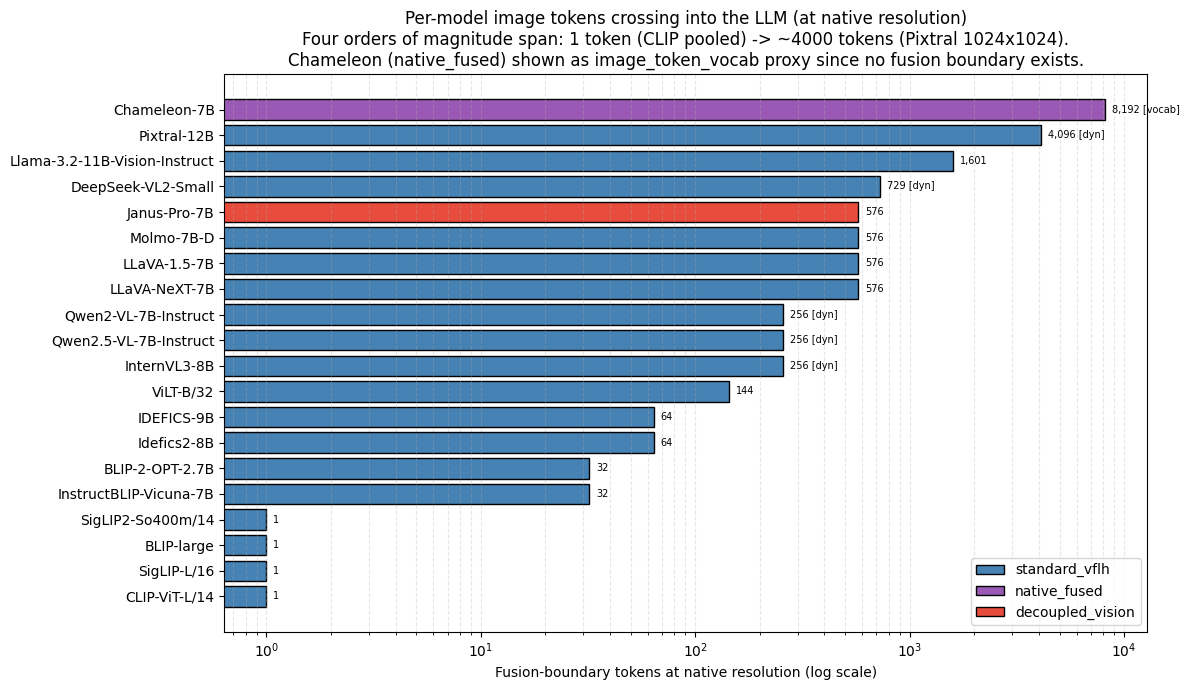

Saved to /workspace/code_active/outputs/figures/nb05_tokens_at_native_bar.png


In [11]:
if results:
    plot_df = tok_df.copy()
    # For native_fused (Chameleon) where tokens is None, plot the image_token_vocab as a fallback for visibility
    plot_df['display_tokens'] = plot_df['tokens_at_native'].fillna(plot_df['image_token_vocab']).fillna(1).astype(int)
    plot_df = plot_df.sort_values('display_tokens').reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 7))
    schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}
    bar_colors = [schema_colors.get(s, 'gray') for s in plot_df['schema']]
    bars = ax.barh(plot_df['name'], plot_df['display_tokens'].clip(lower=1), color=bar_colors, edgecolor='black')
    ax.set_xscale('log')
    ax.set_xlabel('Fusion-boundary tokens at native resolution (log scale)')
    ax.set_title('Per-model image tokens crossing into the LLM (at native resolution)\n'
                 'Four orders of magnitude span: 1 token (CLIP pooled) -> ~4000 tokens (Pixtral 1024x1024).\n'
                 'Chameleon (native_fused) shown as image_token_vocab proxy since no fusion boundary exists.')
    for bar, row in zip(bars, plot_df.itertuples()):
        marker = ' [dyn]' if row.dynamic else ''
        marker = ' [vocab]' if row.schema == 'native_fused' else marker
        ax.annotate(f'{int(bar.get_width()):,}{marker}',
                    xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords='offset points', va='center', fontsize=7)
    from matplotlib.patches import Patch
    legend_handles = [Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()]
    ax.legend(handles=legend_handles, loc='lower right')
    ax.grid(True, which='both', axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb05_tokens_at_native_bar.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb05_tokens_at_native_bar.png"}')

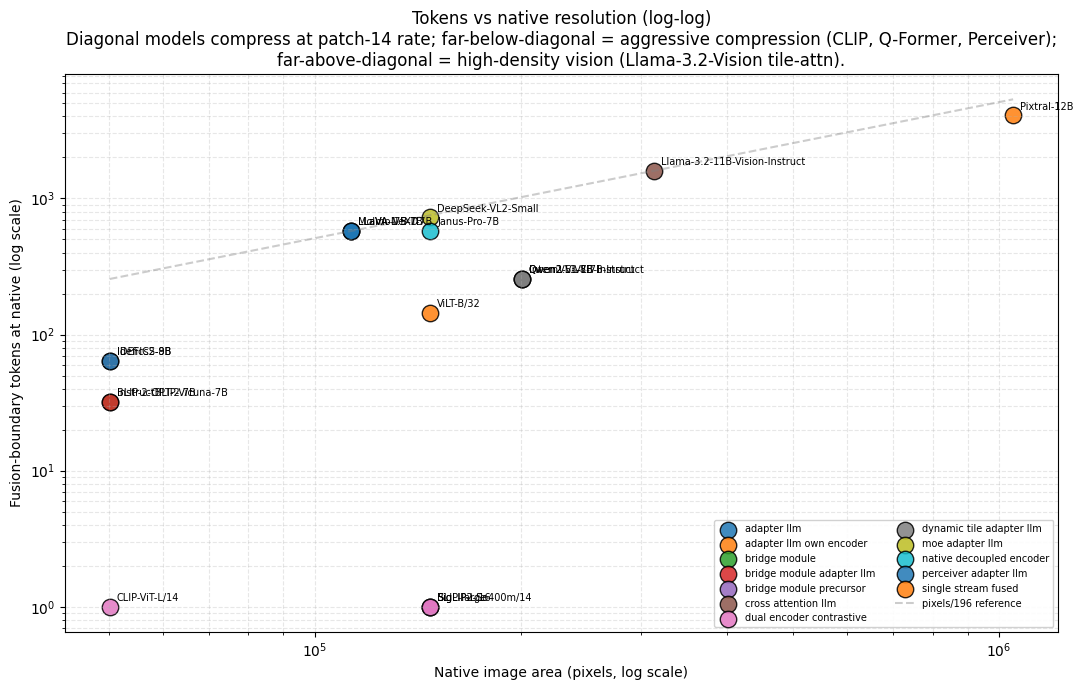

Saved to /workspace/code_active/outputs/figures/nb05_tokens_vs_resolution_scatter.png


In [12]:
if results:
    # Tokens vs native resolution (pixels) — log-log
    scatter_df = tok_df.dropna(subset=['tokens_at_native']).copy()
    scatter_df = scatter_df[scatter_df['tokens_at_native'] > 0]
    fig, ax = plt.subplots(figsize=(11, 7))
    families = sorted(scatter_df['family'].unique())
    cmap = plt.get_cmap('tab10')
    for i, fam in enumerate(families):
        d = scatter_df[scatter_df['family'] == fam]
        ax.scatter(d['native_pixels'], d['tokens_at_native'], s=140, color=cmap(i % 10), edgecolor='black', alpha=0.85, label=fam.replace('_', ' '))
        for _, row in d.iterrows():
            ax.annotate(row['name'], (row['native_pixels'], row['tokens_at_native']),
                        xytext=(5, 4), textcoords='offset points', fontsize=7)
    # Diagonal: tokens = pixels / 196 (LLaVA / Pixtral-like passthrough at patch-14)
    px_range = np.array([scatter_df['native_pixels'].min(), scatter_df['native_pixels'].max()])
    ax.plot(px_range, px_range / 196, '--', color='gray', alpha=0.4, label='pixels/196 reference')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Native image area (pixels, log scale)')
    ax.set_ylabel('Fusion-boundary tokens at native (log scale)')
    ax.set_title('Tokens vs native resolution (log-log)\n'
                 'Diagonal models compress at patch-14 rate; far-below-diagonal = aggressive compression (CLIP, Q-Former, Perceiver);\n'
                 'far-above-diagonal = high-density vision (Llama-3.2-Vision tile-attn).')
    ax.legend(loc='lower right', fontsize=7, framealpha=0.9, ncol=2)
    ax.grid(True, which='both', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb05_tokens_vs_resolution_scatter.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb05_tokens_vs_resolution_scatter.png"}')

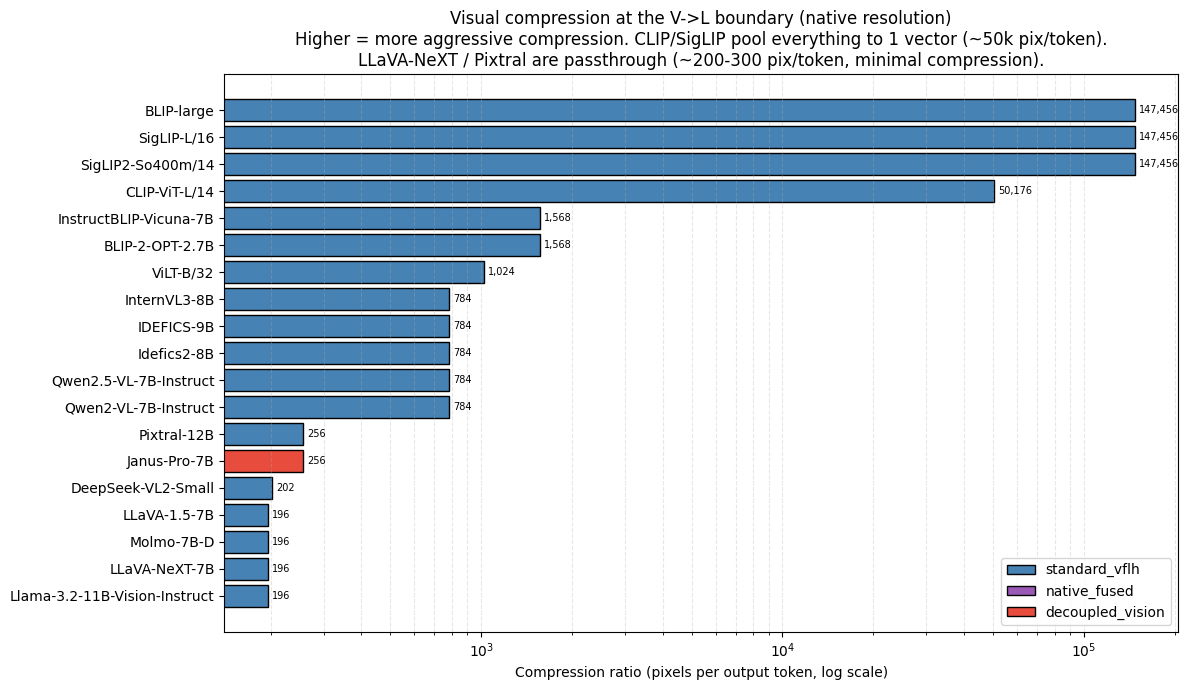

Saved to /workspace/code_active/outputs/figures/nb05_compression_ratio_bar.png


In [13]:
if results:
    # Compression-ratio bar - pixels per token at native; higher = more aggressive compression
    cr_df = tok_df.dropna(subset=['compression_ratio_pix_per_token']).copy()
    cr_df = cr_df[cr_df['compression_ratio_pix_per_token'] > 0].sort_values('compression_ratio_pix_per_token').reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 7))
    schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}
    bar_colors = [schema_colors.get(s, 'gray') for s in cr_df['schema']]
    bars = ax.barh(cr_df['name'], cr_df['compression_ratio_pix_per_token'], color=bar_colors, edgecolor='black')
    ax.set_xscale('log')
    ax.set_xlabel('Compression ratio (pixels per output token, log scale)')
    ax.set_title('Visual compression at the V->L boundary (native resolution)\n'
                 'Higher = more aggressive compression. CLIP/SigLIP pool everything to 1 vector (~50k pix/token).\n'
                 'LLaVA-NeXT / Pixtral are passthrough (~200-300 pix/token, minimal compression).')
    for bar, val in zip(bars, cr_df['compression_ratio_pix_per_token']):
        ax.annotate(f'{val:,.0f}', xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                    xytext=(3, 0), textcoords='offset points', va='center', fontsize=7)
    from matplotlib.patches import Patch
    legend_handles = [Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()]
    ax.legend(handles=legend_handles, loc='lower right')
    ax.grid(True, which='both', axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb05_compression_ratio_bar.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb05_compression_ratio_bar.png"}')

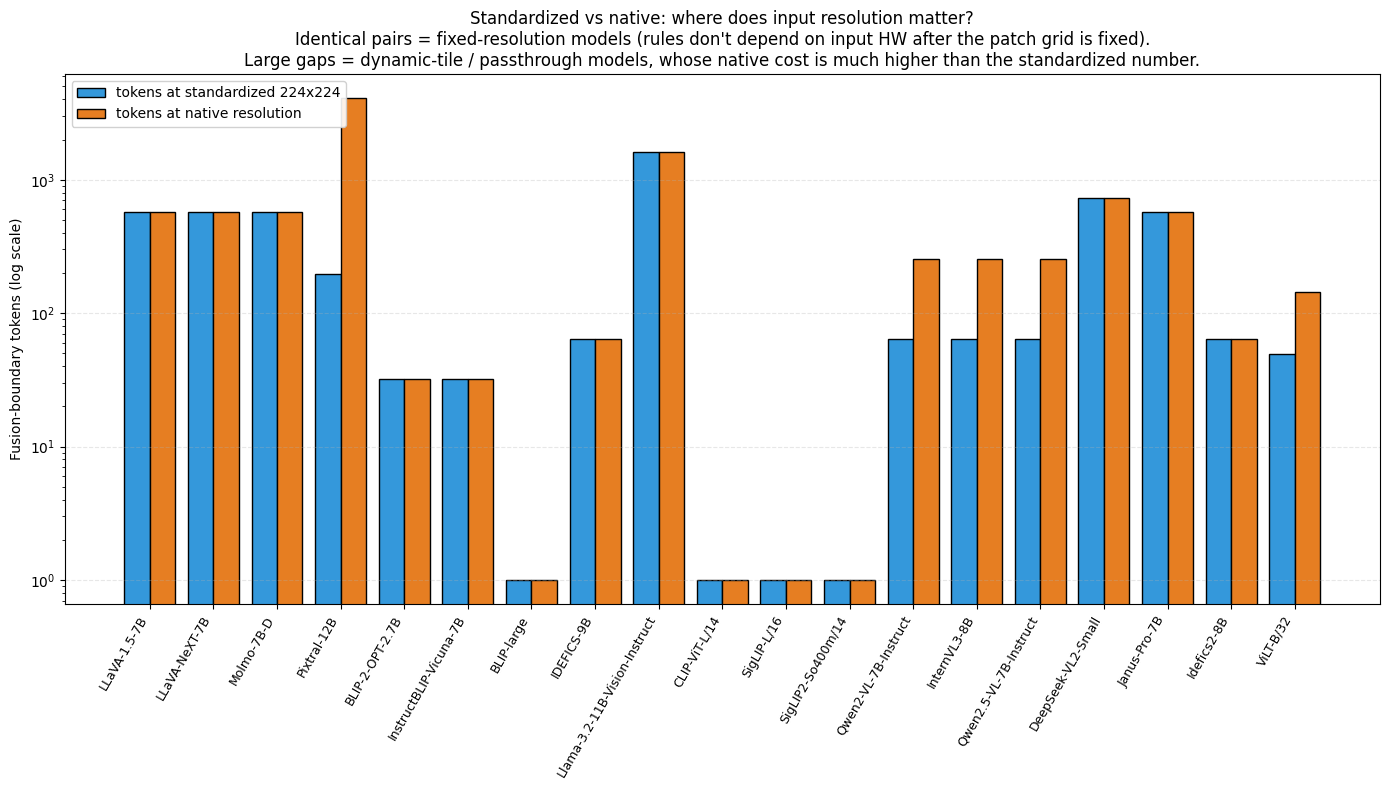

Saved to /workspace/code_active/outputs/figures/nb05_tokens_224_vs_native_sidebyside.png


In [14]:
if results:
    # Side-by-side tokens-at-224 vs tokens-at-native bar
    sb = tok_df.dropna(subset=['tokens_at_224', 'tokens_at_native']).copy()
    sb = sb.sort_values(['family', 'year', 'name']).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 8))
    x = np.arange(len(sb))
    width = 0.4
    ax.bar(x - width/2, sb['tokens_at_224'].clip(lower=1), width=width, color='#3498DB', edgecolor='black', label='tokens at standardized 224x224')
    ax.bar(x + width/2, sb['tokens_at_native'].clip(lower=1), width=width, color='#E67E22', edgecolor='black', label='tokens at native resolution')
    ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels(sb['name'], rotation=60, ha='right', fontsize=9)
    ax.set_ylabel('Fusion-boundary tokens (log scale)')
    ax.set_title('Standardized vs native: where does input resolution matter?\n'
                 'Identical pairs = fixed-resolution models (rules don\'t depend on input HW after the patch grid is fixed).\n'
                 'Large gaps = dynamic-tile / passthrough models, whose native cost is much higher than the standardized number.')
    ax.legend(loc='upper left', framealpha=0.9)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb05_tokens_224_vs_native_sidebyside.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb05_tokens_224_vs_native_sidebyside.png"}')

---
## 9. Per-family summary statistics

Aggregate by family — median / min / max tokens at native resolution. The median is the headline number per family; min/max shows within-family variance (mostly 0 for fixed families, large for dynamic-tile families).

In [15]:
if results:
    fam_summary = tok_df.copy()
    # For aggregation, treat Chameleon's None as 'missing' (don't include in min/median/max)
    fam_native = fam_summary['tokens_at_native']
    fam_summary = fam_summary.groupby('family').agg(
        n_models           = ('name', 'count'),
        min_tokens_native  = ('tokens_at_native', 'min'),
        median_tokens_native = ('tokens_at_native', 'median'),
        max_tokens_native  = ('tokens_at_native', 'max'),
        median_tokens_224  = ('tokens_at_224', 'median'),
        median_compression = ('compression_ratio_pix_per_token', 'median'),
        any_dynamic        = ('dynamic', 'any'),
        models             = ('name', lambda s: ', '.join(s)),
    ).round(1).sort_values('median_tokens_native', na_position='last')
fam_summary if results else None

,n_models,min_tokens_native,median_tokens_native,max_tokens_native,median_tokens_224,median_compression,any_dynamic,models
family,,,,,,,,
dual_encoder_contrastive,3,1.0,1.0,1.0,1.0,147456.0,False,"CLIP-ViT-L/14, SigLIP-L/16, SigLIP2-So400m/14"
bridge_module_precursor,1,1.0,1.0,1.0,1.0,147456.0,False,BLIP-large
bridge_module_adapter_llm,1,32.0,32.0,32.0,32.0,1568.0,False,InstructBLIP-Vicuna-7B
bridge_module,1,32.0,32.0,32.0,32.0,1568.0,False,BLIP-2-OPT-2.7B
perceiver_adapter_llm,1,64.0,64.0,64.0,64.0,784.0,False,Idefics2-8B
single_stream_fused,1,144.0,144.0,144.0,49.0,1024.0,False,ViLT-B/32
dynamic_tile_adapter_llm,3,256.0,256.0,256.0,64.0,784.0,True,"Qwen2-VL-7B-Instruct, Qwen2.5-VL-7B-Instruct, ..."
adapter_llm,3,576.0,576.0,576.0,576.0,196.0,False,"LLaVA-1.5-7B, LLaVA-NeXT-7B, Molmo-7B-D"
native_decoupled_encoder,1,576.0,576.0,576.0,576.0,256.0,False,Janus-Pro-7B


---
## 10. Interpretation — the bandwidth-bottleneck story in one paragraph

**The headline finding for the paper:**

Across 20 vision-language models spanning 2021-2026, fusion-boundary token count varies by **four orders of magnitude** — from 1 token (CLIP / SigLIP / BLIP-large, pooled contrastive design) to ~4000 tokens (Pixtral at native 1024x1024, passthrough on its own from-scratch encoder). This is far wider variance than the parameter axis (~70x range, ViLT-117M to DeepSeek-VL2-27B).

**Three eras visible in the data:**
* **2021-2022 — bottleneck era.** CLIP / SigLIP / BLIP-1 use 1-token pooling to fit the contrastive loss. Implicit assumption: a single global vector captures enough visual semantics.
* **2023 — fixed-compression era.** BLIP-2 / InstructBLIP introduce the Q-Former (32 queries). IDEFICS / Idefics2 use Perceiver Resamplers (64 latents). These are explicit, learned bandwidth bottlenecks - the V->L interface becomes a design parameter.
* **2024-2025 — passthrough + dynamic era.** LLaVA family (576 tokens) removes the bottleneck entirely; Qwen2-VL / Qwen2.5-VL / InternVL3 / Pixtral / DeepSeek-VL2 make token count input-dependent. The bandwidth ceiling explodes from 64 to ~4000.

**Why this matters for the paper:**

Language-dominant models with many tokens at native resolution (Qwen2-VL ~256 after 2x2 merger but up to ~5800 with dynamic tiling on high-detail input; Pixtral 4096) are expensive at inference EVEN THOUGH their LLM is 'only' 7B parameters. The cost is in the **attention over visual tokens** — quadratic in token count. A 7B LLM processing 4000 vision tokens does roughly 16M attention entries per layer; with 32 layers and a Q-Former-style 32-token bridge it would be ~32k. The difference is a 500x reduction in attention cost per forward pass for the same parametric capacity.

This is the **bandwidth axis** of the asymmetry argument: the V->L bridge design is a more important determinant of deployment cost than the LLM size, and varies by orders of magnitude across the field. The paper's claim is that this axis correlates with benchmark performance better than parameter count does — verified in notebook 13.

---
## 11. Failures (debugging)

If any model failed to compute tokens, it shows here. Token-count computation is purely arithmetic from `model_spec.native_image_hw` and `model_spec.family` — the only ways it can fail are:
* `model_spec.native_image_hw` is malformed (not a 2-tuple).
* A new family was added to `models.py` without a matching entry in `count_fusion_boundary_tokens` -> returns `None`, not an error.

If `count_fusion_boundary_tokens` returns `None` for an unexpected model, add a rule for that family in `vlm_audit/metrics.py:count_fusion_boundary_tokens`.

In [16]:
if failures:
    failures_df = pd.DataFrame(failures)
    print(f'{len(failures)} failures:')
    failures_df
else:
    print('No failures - all 20 models computed token counts.')

# Also flag any None tokens_at_native that aren't Chameleon - those are silent gaps
if results:
    silent_gaps = tok_df[tok_df['tokens_at_native'].isna() & (tok_df['schema'] != 'native_fused')]
    if len(silent_gaps) > 0:
        print(f'\nWARN: {len(silent_gaps)} models returned None for tokens_at_native and are NOT native_fused:')
        print(silent_gaps[['name', 'family', 'schema']])
        print('  -> add a rule for this family in vlm_audit/metrics.py:count_fusion_boundary_tokens')
    else:
        print('  No silent gaps (every standard / decoupled model has a token count).')

No failures - all 20 models computed token counts.
  No silent gaps (every standard / decoupled model has a token count).


---
## 12. Save the master token table to disk

The per-model JSONs are already saved (incrementally merged by `run_full_audit`). We additionally save the aggregated DataFrame as CSV + the family summary.

In [17]:
if not results:
    print('Nothing to save - no successful results.')
else:
    csv_master = MEASUREMENT_DIR / 'nb05_token_summary.csv'
    csv_family = MEASUREMENT_DIR / 'nb05_family_token_summary.csv'
    tok_df.to_csv(csv_master, index=False)
    fam_summary.to_csv(csv_family)
    print(f'Saved: {csv_master}')
    print(f'Saved: {csv_family}')
    print(f'Per-model JSONs: {MEASUREMENT_DIR}/<hf_id>.json (output_tokens fields merged in)')
    print(f'Verbose .txt logs: {LOG_DIR}/')
    print(f'Figures: {FIG_DIR}/nb05_*.png')

Saved: /workspace/code_active/outputs/measurements/nb05_token_summary.csv
Saved: /workspace/code_active/outputs/measurements/nb05_family_token_summary.csv
Per-model JSONs: /workspace/code_active/outputs/measurements/<hf_id>.json (output_tokens fields merged in)
Verbose .txt logs: /workspace/code_active/outputs/logs/
Figures: /workspace/code_active/outputs/figures/nb05_*.png


---
## Next steps

* If everything above looks right -> continue to **`06_master_table.ipynb`** to merge params / FLOPs / memory / tokens into one wide master.csv.
* If a token count looks wrong (e.g. Qwen2-VL native shows 64 when you expected 256) -> check `count_fusion_boundary_tokens` for the family's compression rule. Qwen2-VL's 2x2 merger means `(H/14)^2 / 4` post-merger, or `(H/28)^2` equivalently.
* If you added a new model in `models.py` and the script silently returned `None` for it -> add a `family ==` branch in `vlm_audit/metrics.py:count_fusion_boundary_tokens`.
* The bandwidth correlation analysis (does this axis predict benchmark performance?) lives in **notebook 13** (`13_benchmark_correlations_F11_F14.ipynb`).

*End of notebook 05 (verbose v3-style, CPU-only). Pipeline: 00 setup -> 02 params -> 03 FLOPs -> 04 memory -> **05 tokens** -> 06 master table -> 13 correlations.*